In [1]:
def build_feature_map():
    feature_map = {}
    idx = 0

    # --------------------------------------------------
    # Mechanism type (11)
    # --------------------------------------------------
    for i in range(11):
        feature_map[idx] = f"mechanism_type={i}"
        idx += 1

    # --------------------------------------------------
    # Atom fingerprints (4 atoms × 35 bits)
    # --------------------------------------------------
    charge = ["charge=neg", "charge=pos"]
    hcount = ["H=0", "H=1", "H=2", "H>2"]
    hybrid = ["hybrid=sp", "hybrid=sp2", "hybrid=sp3"]
    elements = [
        "element=alkali",
        "element=B",
        "element=C",
        "element=N",
        "element=O",
        "element=F",
        "element=Mg",
        "element=Al",
        "element=Si",
        "element=P",
        "element=S",
        "element=Cl",
        "element=Br",
        "element=I",
        "element=transition_metal",
    ]
    aromatic = ["aromatic=no", "aromatic=yes"]
    adjacency = [
        "adj=C+",
        "adj=C-",
        "adj=CH",
        "adj=C-EN",
        "adj=C=EN",
        "adj=EN",
        "adj=EP",
        "adj=CH0",
        "adj=C(sp/sp2)",
    ]
    three_membered_ring = ["ring=3"]

    for atom_i in range(1, 5):
        prefix = f"atom{atom_i}"

        for label in charge:
            feature_map[idx] = f"{prefix}.{label}"
            idx += 1

        for label in hcount:
            feature_map[idx] = f"{prefix}.{label}"
            idx += 1

        for label in hybrid:
            feature_map[idx] = f"{prefix}.{label}"
            idx += 1

        for label in elements:
            feature_map[idx] = f"{prefix}.{label}"
            idx += 1

        for label in aromatic:
            feature_map[idx] = f"{prefix}.{label}"
            idx += 1

        for label in adjacency:
            feature_map[idx] = f"{prefix}.{label}"
            idx += 1
            
        for label in three_membered_ring:
            feature_map[idx] = f"{prefix}.{label}"
            idx += 1

    # --------------------------------------------------
    # Bond 1 (4)
    # --------------------------------------------------
    for label in ["bond1=single", "bond1=double", "bond1=triple", "bond1=none"]:
        feature_map[idx] = label
        idx += 1

    # --------------------------------------------------
    # Bond 2 (4)
    # --------------------------------------------------
    for label in ["bond2=single", "bond2=double", "bond2=triple", "bond2=none"]:
        feature_map[idx] = label
        idx += 1

    # --------------------------------------------------
    # Ring size (5)
    # --------------------------------------------------
    for label in ["ring=3", "ring=4", "ring=5", "ring=6", "ring>=7"]:
        feature_map[idx] = label
        idx += 1

    return feature_map


In [2]:
print(feature_map := build_feature_map())

{0: 'mechanism_type=0', 1: 'mechanism_type=1', 2: 'mechanism_type=2', 3: 'mechanism_type=3', 4: 'mechanism_type=4', 5: 'mechanism_type=5', 6: 'mechanism_type=6', 7: 'mechanism_type=7', 8: 'mechanism_type=8', 9: 'mechanism_type=9', 10: 'mechanism_type=10', 11: 'atom1.charge=neg', 12: 'atom1.charge=pos', 13: 'atom1.H=0', 14: 'atom1.H=1', 15: 'atom1.H=2', 16: 'atom1.H>2', 17: 'atom1.hybrid=sp', 18: 'atom1.hybrid=sp2', 19: 'atom1.hybrid=sp3', 20: 'atom1.element=alkali', 21: 'atom1.element=B', 22: 'atom1.element=C', 23: 'atom1.element=N', 24: 'atom1.element=O', 25: 'atom1.element=F', 26: 'atom1.element=Mg', 27: 'atom1.element=Al', 28: 'atom1.element=Si', 29: 'atom1.element=P', 30: 'atom1.element=S', 31: 'atom1.element=Cl', 32: 'atom1.element=Br', 33: 'atom1.element=I', 34: 'atom1.element=transition_metal', 35: 'atom1.aromatic=no', 36: 'atom1.aromatic=yes', 37: 'atom1.adj=C+', 38: 'atom1.adj=C-', 39: 'atom1.adj=CH', 40: 'atom1.adj=C-EN', 41: 'atom1.adj=C=EN', 42: 'atom1.adj=EN', 43: 'atom1.a

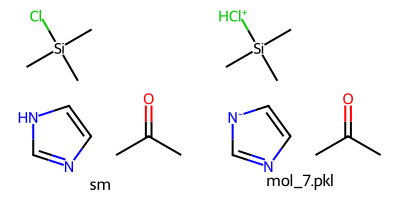

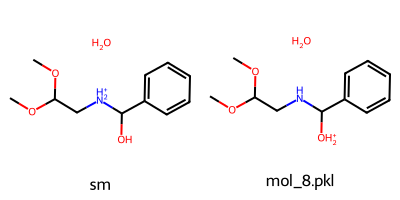

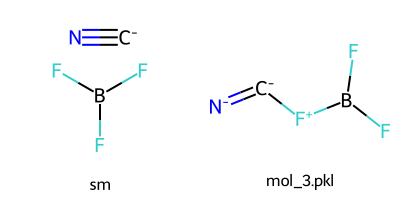

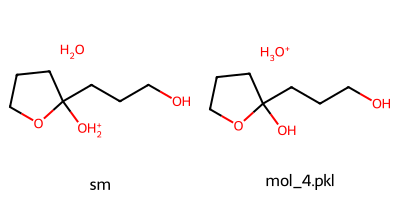

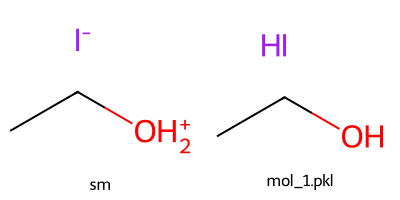

Prepared 5 examples


In [3]:
# === XGBoost exact decision-path explanation (LIST-BASED FEATURES) ===

from platform import node
import xgboost as xgb
import json
import math

# ------------------------------------------------------------------
# 0. Build feature map
# ------------------------------------------------------------------
feature_map = build_feature_map()

# ------------------------------------------------------------------
# 1. Load model
# ------------------------------------------------------------------
booster = xgb.Booster()
booster.load_model("models/v101f2/xg_model.json")

trees = booster.get_dump(dump_format="json", with_stats=True)
trees = [json.loads(t) for t in trees]

# ------------------------------------------------------------------
# 2. Single sample as LIST / ARRAY
# ------------------------------------------------------------------
# Random examples from training_sets/20260202

import os
import pickle
import random

from rdkit.Chem import Draw
from IPython.display import display

from shared.ml_helper import make_fingerprint

training_dir = "training_sets/20260202"
num_examples = 5

# Pick random folders and random valid mechanisms inside them
subdirs = [d for d in os.listdir(training_dir) if os.path.isdir(os.path.join(training_dir, d))]
if not subdirs:
    raise RuntimeError(f"No subdirectories found in {training_dir}")

rng = random.Random()

gemini_examples = []

# String payload for Gemini explanations
gemini_payload = ""

fingerprints_list = []

for _ in range(num_examples):
    while True:
        subdir = rng.choice(subdirs)
        folder_path = os.path.join(training_dir, subdir)
        json_path = os.path.join(folder_path, "data.json")
        sm_path = os.path.join(folder_path, "sm.pkl")
        if not (os.path.exists(json_path) and os.path.exists(sm_path)):
            continue

        with open(json_path, "r") as f:
            data = json.load(f)

        choices = data.get("choices", {})
        valid_choices = [info for info in choices.values() if info.get("probable") is not None and info.get("mechanism") is not None]
        if not valid_choices:
            continue

        info = rng.choice(valid_choices)
        mechanism = info["mechanism"]

        with open(sm_path, "rb") as f:
            sm = pickle.load(f)

        x = make_fingerprint(sm, mechanism)
        fingerprints_list.append(x)
        break

    # Draw starting material and a random product (mol_*.pkl)
    mol_files = [f for f in os.listdir(folder_path) if f.startswith("mol_") and f.endswith(".pkl")]
    product_mol = None
    product_label = None
    if mol_files:
        mol_file = rng.choice(mol_files)
        with open(os.path.join(folder_path, mol_file), "rb") as f:
            product_mol = pickle.load(f)
        product_label = mol_file

    if product_mol is not None:
        img = Draw.MolsToGridImage([sm, product_mol], molsPerRow=2, legends=["sm", product_label])
        display(img)

    gemini_examples.append({
        "folder": folder_path,
        "mechanism": mechanism,
        "fingerprint": x,
        "product": product_label,
    })

print(f"Prepared {len(gemini_examples)} examples")
# ------------------------------------------------------------------
# 3. Tree-walking function (list-based)
# ------------------------------------------------------------------
def walk_tree(node, x, path):
    # Leaf node
    if "leaf" in node:
        return node["leaf"], path

    feature = node["split"]          # e.g. "f17"
    threshold = node["split_condition"]

    # Extract integer index
    idx = int(feature[1:])
    label = feature_map[idx]
    label = idx
    value = x[idx]
  

    if value < threshold:
        next_id = node["yes"]
        # decision = f"{label} ({feature}) = 0 → yes-branch"
        decision = f"{label} ({feature}) = 0"
    else:
        next_id = node["no"]
        # decision = f"{label} ({feature}) = 1 → no-branch"
        decision = f"{label} ({feature}) = 1"
    path.append(decision)

    for child in node["children"]:
        if child["nodeid"] == next_id:
            return walk_tree(child, x, path)

    raise RuntimeError("Child node not found")

# ------------------------------------------------------------------
# 4. Explain prediction
# ------------------------------------------------------------------
import json

config = json.loads(booster.save_config())
base_score = float(
    config["learner"]["learner_model_param"]["base_score"]
)

# learning rate (eta)
def log(*args):
    global gemini_payload
    line = ' '.join(str(a) for a in args)
    gemini_payload += line + '\n'

gb = config["learner"]["gradient_booster"]
tree_params = gb.get("tree_train_param", {})

learning_rate = tree_params.get("learning_rate")
if learning_rate is None:
    learning_rate = tree_params.get("eta")

learning_rate = float(learning_rate)

raw_score = base_score

for i, tree in enumerate(trees):
    leaf_value, path = walk_tree(tree, x, [])

    contribution = learning_rate * leaf_value

    log(f"Tree {i}")
    for step in path:
        log("  •", step)
    log(f"  → Leaf value: {leaf_value:.6f}")
    log(f"  → Contribution (η × leaf): {contribution:.6f}\n")

    raw_score += contribution

probability = 1.0 / (1.0 + math.exp(-raw_score))

log("=" * 60)
log(f"Final raw score (log-odds): {raw_score:.6f}")
log(f"Predicted probability: {probability:.6f}")


In [4]:
import json
import math

output = ""

# ------------------------------------------------------------------
# 1. Extract base_score and learning_rate from booster config
# ------------------------------------------------------------------
config = json.loads(booster.save_config())

base_score = float(
    config["learner"]["learner_model_param"]["base_score"]
)

tree_params = config["learner"]["gradient_booster"]["tree_train_param"]

learning_rate = tree_params.get("learning_rate", tree_params.get("eta"))
learning_rate = float(learning_rate)

# ------------------------------------------------------------------
# 2. Walk trees, collect contributions
# ------------------------------------------------------------------
tree_contributions = []

raw_score = base_score

for idx, x in enumerate(fingerprints_list):
    for i, tree in enumerate(trees):
        leaf_value, path = walk_tree(tree, x, [])

        contribution = learning_rate * leaf_value
        raw_score += contribution

        tree_contributions.append({
            "tree": i,
            "leaf_value": leaf_value,
            "contribution": contribution,
            "abs_contribution": abs(contribution),
            "path": path,
        })

    # ------------------------------------------------------------------
    # 3. Rank trees by absolute contribution
    # ------------------------------------------------------------------
    tree_contributions.sort(
        key=lambda d: d["abs_contribution"],
        reverse=True
    )

    # ------------------------------------------------------------------
    # 4. Pretty print top contributors
    # ------------------------------------------------------------------
    TOP_K = 5

    print("=" * 70)

    print(f"Top {TOP_K} trees by contribution for molecule {idx + 1}")
    output += f"Top {TOP_K} trees by contribution for molecule {idx + 1}\n"

    output += "=" * 70 + "\n"

    for entry in tree_contributions[:TOP_K]:
        print(f"Tree {entry['tree']}")
        output += f"Tree {entry['tree']}\n"
        for step in entry["path"]:
            print("  •", step)
            output += f"  • {step}\n"
        print(f"  → Leaf value: {entry['leaf_value']:.6f}")
        output += f"  → Leaf value: {entry['leaf_value']:.6f}\n"
        print(f"  → Contribution (η × leaf): {entry['contribution']:.6f}")
        output += f"  → Contribution (η × leaf): {entry['contribution']:.6f}\n\n"
        print()

    # ------------------------------------------------------------------
    # 5. Final probability (sanity check)
    # ------------------------------------------------------------------
    probability = 1.0 / (1.0 + math.exp(-raw_score))

    print("=" * 70)
    print(f"Final raw score (log-odds): {raw_score:.6f}")
    output += f"Final raw score (log-odds): {raw_score:.6f}\n"
    print(f"Predicted probability: {probability:.6f}")
    output += f"Predicted probability: {probability:.6f}\n"


Top 5 trees by contribution for molecule 1
Tree 4
  • 148 (f148) = 1
  • 120 (f120) = 1
  • 18 (f18) = 0
  • 24 (f24) = 0
  • 81 (f81) = 0
  • 131 (f131) = 1
  → Leaf value: -0.447132
  → Contribution (η × leaf): -0.134139

Tree 3
  • 147 (f147) = 1
  • 120 (f120) = 1
  • 163 (f163) = 1
  → Leaf value: -0.397237
  → Contribution (η × leaf): -0.119171

Tree 17
  • 48 (f48) = 0
  • 61 (f61) = 0
  • 57 (f57) = 0
  • 2 (f2) = 1
  → Leaf value: -0.380275
  → Contribution (η × leaf): -0.114083

Tree 8
  • 48 (f48) = 0
  • 163 (f163) = 1
  • 11 (f11) = 0
  • 156 (f156) = 0
  • 93 (f93) = 0
  • 88 (f88) = 0
  • 23 (f23) = 0
  → Leaf value: -0.324492
  → Contribution (η × leaf): -0.097348

Tree 13
  • 100 (f100) = 1
  • 83 (f83) = 0
  → Leaf value: -0.323226
  → Contribution (η × leaf): -0.096968

Final raw score (log-odds): -1.460135
Predicted probability: 0.188447
Top 5 trees by contribution for molecule 2
Tree 2
  • 147 (f147) = 1
  • 120 (f120) = 1
  • 22 (f22) = 0
  • 13 (f13) = 0
  • 131 

In [5]:
f_map = build_feature_map()

In [6]:
f_map[1]

'mechanism_type=1'

In [7]:
def extract_rules(node, path_conditions):
    rules = []

    # Leaf
    if "leaf" in node:
        rules.append({
            "conditions": tuple(sorted(path_conditions)),
            "leaf": node["leaf"],
            "cover": node.get("cover", 0)
        })
        return rules

    feature = node["split"]
    threshold = node["split_condition"]
    idx = int(feature[1:])

    # YES branch (< threshold)
    yes_condition = f"{idx}=0"
    for child in node["children"]:
        if child["nodeid"] == node["yes"]:
            rules += extract_rules(
                child,
                path_conditions + [yes_condition]
            )

    # NO branch (>= threshold)
    no_condition = f"{idx}=1"
    for child in node["children"]:
        if child["nodeid"] == node["no"]:
            rules += extract_rules(
                child,
                path_conditions + [no_condition]
            )

    return rules

In [8]:
all_rules = []

for tree in trees:
    rules = extract_rules(tree, [])
    all_rules.extend(rules)

In [9]:
print(all_rules[:5])

[{'conditions': ('100=0', '117=0', '131=0', '147=0', '160=0', '163=0', '164=0', '32=0', '41=0', '48=0'), 'leaf': 0.238461092, 'cover': 878.089355}, {'conditions': ('100=0', '117=0', '131=1', '147=0', '160=0', '163=0', '164=0', '32=0', '41=0', '48=0'), 'leaf': -0.190878391, 'cover': 52.6414948}, {'conditions': ('100=0', '117=0', '147=0', '160=1', '163=0', '164=0', '32=0', '41=0', '43=0', '48=0'), 'leaf': 0.422486633, 'cover': 347.287628}, {'conditions': ('100=0', '117=0', '147=0', '160=1', '163=0', '164=0', '32=0', '41=0', '43=1', '48=0'), 'leaf': -0.542025626, 'cover': 3.16823816}, {'conditions': ('100=1', '117=0', '147=0', '163=0', '164=0', '32=0', '41=0', '47=0', '48=0'), 'leaf': -0.669501722, 'cover': 15.3537693}]


In [10]:
from collections import defaultdict
import statistics

rule_stats = defaultdict(lambda: {"leafs": [], "cover": 0})

for r in all_rules:
    key = r["conditions"]

    rule_stats[key]["leafs"].append(r["leaf"])
    rule_stats[key]["cover"] += r["cover"]

In [11]:
heuristics = []

for cond, stats in rule_stats.items():

    mean_leaf = statistics.mean(stats["leafs"])
    trees_supporting = len(stats["leafs"])
    cover = stats["cover"]

    strength = abs(mean_leaf) * trees_supporting

    heuristics.append({
        "conditions": cond,
        "mean_leaf": mean_leaf,
        "trees": trees_supporting,
        "cover": cover,
        "strength": strength
    })

In [12]:
heuristics.sort(key=lambda x: x["strength"], reverse=True)

In [13]:
for h in heuristics[:30]:

    cond_str = " AND ".join(h["conditions"])

    print("RULE")
    print(" IF", cond_str)
    print(f" THEN mean leaf = {h['mean_leaf']:.3f}")
    print(f" trees = {h['trees']}")
    print(f" cover = {h['cover']}")
    print(f" strength = {h['strength']:.3f}")
    print()

RULE
 IF 11=1 AND 120=0 AND 130=0 AND 147=1 AND 150=1
 THEN mean leaf = -0.425
 trees = 4
 cover = 17.127252579999997
 strength = 1.701

RULE
 IF 11=1 AND 120=0 AND 130=1 AND 147=1 AND 78=0
 THEN mean leaf = -0.481
 trees = 3
 cover = 47.8424711
 strength = 1.443

RULE
 IF 117=0 AND 11=0 AND 120=0 AND 147=0 AND 163=0 AND 164=1 AND 48=0 AND 63=0
 THEN mean leaf = -0.600
 trees = 2
 cover = 129.9232101
 strength = 1.199

RULE
 IF 0=0 AND 11=0 AND 126=0 AND 147=0 AND 164=0 AND 1=0 AND 22=0 AND 32=1 AND 48=1 AND 56=0
 THEN mean leaf = -0.597
 trees = 2
 cover = 2.92083001
 strength = 1.194

RULE
 IF 11=1 AND 120=0 AND 147=1 AND 148=1 AND 77=1 AND 90=1
 THEN mean leaf = -0.296
 trees = 4
 cover = 7.37162042
 strength = 1.184

RULE
 IF 120=1 AND 148=1 AND 160=1 AND 18=1 AND 78=1
 THEN mean leaf = 0.291
 trees = 4
 cover = 18.93059325
 strength = 1.165

RULE
 IF 117=1 AND 147=0 AND 156=0 AND 16=0 AND 18=0 AND 54=1
 THEN mean leaf = -0.583
 trees = 2
 cover = 40.8058261
 strength = 1.165

RULE

In [14]:
from collections import defaultdict

bit_scores = defaultdict(float)
bit_counts = defaultdict(int)

for h in heuristics:

    score = h["mean_leaf"] * h["trees"]

    for cond in h["conditions"]:

        bit, val = cond.split("=")
        bit = int(bit)
        val = int(val)

        # treat presence and absence separately
        key = (bit, val)

        bit_scores[key] += score
        bit_counts[key] += 1

In [15]:
motifs = []

for (bit, val), score in bit_scores.items():

    motifs.append({
        "bit": bit,
        "value": val,
        "score": score,
        "count": bit_counts[(bit,val)]
    })

motifs.sort(key=lambda x: abs(x["score"]), reverse=True)

In [16]:
motifs

[{'bit': 11, 'value': 0, 'score': -100.47186105677427, 'count': 1833},
 {'bit': 120, 'value': 0, 'score': -72.85965845783417, 'count': 1637},
 {'bit': 48, 'value': 0, 'score': -67.48865605859434, 'count': 1478},
 {'bit': 160, 'value': 0, 'score': -30.54479874488099, 'count': 522},
 {'bit': 147, 'value': 0, 'score': -29.616250014585987, 'count': 638},
 {'bit': 40, 'value': 0, 'score': -28.265794763157043, 'count': 619},
 {'bit': 148, 'value': 1, 'score': -27.792284618315993, 'count': 633},
 {'bit': 23, 'value': 0, 'score': -26.3638864740713, 'count': 694},
 {'bit': 13, 'value': 1, 'score': -25.230038904589005, 'count': 860},
 {'bit': 147, 'value': 1, 'score': -24.25509329422405, 'count': 435},
 {'bit': 130, 'value': 0, 'score': -21.196589476083382, 'count': 500},
 {'bit': 57, 'value': 0, 'score': -20.16531302108102, 'count': 595},
 {'bit': 117, 'value': 0, 'score': -19.870159835277015, 'count': 321},
 {'bit': 148, 'value': 0, 'score': -19.84685908169342, 'count': 749},
 {'bit': 163, 'va

In [17]:
from itertools import combinations

pair_scores = defaultdict(float)

for h in heuristics:

    score = h["mean_leaf"] * h["trees"]

    for a,b in combinations(h["conditions"],2):

        key = tuple(sorted([a,b]))
        pair_scores[key] += score

In [18]:
pair_scores

defaultdict(float,
            {('11=1', '120=0'): -9.415394372282002,
             ('11=1', '130=0'): -1.9972945482840048,
             ('11=1', '147=1'): -5.233234551620006,
             ('11=1', '150=1'): -5.384010546100001,
             ('120=0', '130=0'): -9.33219189057,
             ('120=0', '147=1'): -16.710791851516003,
             ('120=0', '150=1'): -2.84971921629,
             ('130=0', '147=1'): -3.0938909571000006,
             ('130=0', '150=1'): -1.5438989311,
             ('147=1', '150=1'): -2.0849402992,
             ('11=1', '130=1'): -0.8737803322000004,
             ('11=1', '78=0'): -3.1737204951360014,
             ('120=0', '130=1'): -1.8640364243500003,
             ('120=0', '78=0'): -0.8168936387799999,
             ('130=1', '147=1'): -3.664736873,
             ('130=1', '78=0'): -2.0791541498000004,
             ('147=1', '78=0'): -3.942862151699998,
             ('117=0', '11=0'): -11.761725773420007,
             ('117=0', '120=0'): -5.378106471246999,


In [19]:
f_map[1]

'mechanism_type=1'

In [20]:
positive = sorted(
    [(k,v) for k,v in pair_scores.items() if v > 0],
    key=lambda x: x[1],
    reverse=True
)

negative = sorted(
    [(k,v) for k,v in pair_scores.items() if v < 0],
    key=lambda x: x[1]
)

In [21]:
print("Top positive motifs")
for (a,b), score in positive[:20]:
    print(f"{f_map[int(a.split('=')[0])]}={a.split('=')[1]} AND {f_map[int(b.split('=')[0])]}={b.split('=')[1]} → {score:.3f}")

print("\nTop negative motifs")
for (a,b), score in negative[:20]:
    print(f"{f_map[int(a.split('=')[0])]}={a.split('=')[1]} AND {f_map[int(b.split('=')[0])]}={b.split('=')[1]} → {score:.3f}")

Top positive motifs
atom2.charge=pos=1 AND mechanism_type=4=1 → 8.990
ring=4=0 AND atom2.charge=pos=1 → 6.953
atom1.charge=neg=1 AND atom2.adj=EN=1 → 5.711
atom1.charge=neg=1 AND atom1.H=0=0 → 5.273
atom2.charge=pos=1 AND atom2.hybrid=sp2=0 → 5.229
atom1.charge=neg=1 AND atom2.charge=pos=1 → 5.163
atom1.adj=C-EN=1 AND atom2.charge=pos=1 → 5.158
atom3.adj=C(sp/sp2)=1 AND atom2.adj=CH=1 → 5.023
atom1.charge=neg=1 AND atom2.hybrid=sp2=0 → 4.872
atom1.H=0=0 AND atom4.adj=EN=0 → 4.850
atom1.adj=C-EN=1 AND atom2.adj=CH=1 → 4.831
atom4.charge=pos=1 AND atom4.element=N=0 → 4.815
atom4.charge=pos=1 AND atom2.H=2=1 → 4.719
atom1.H=0=0 AND atom2.adj=EN=0 → 4.716
atom4.charge=pos=1 AND atom2.adj=C-EN=0 → 4.623
atom4.element=N=0 AND atom1.H=0=0 → 4.527
ring=4=0 AND atom1.adj=C-EN=1 → 4.412
atom4.charge=pos=1 AND bond2=double=1 → 4.382
atom2.charge=pos=1 AND atom2.element=alkali=0 → 4.347
atom4.charge=pos=1 AND atom4.H=0=1 → 4.296

Top negative motifs
atom1.charge=neg=0 AND atom4.charge=pos=0 → -35.

In [22]:
import numpy as np
import pandas as pd

def conditional_probabilities(model, X, target_feature="f1"):
    
    results = []
    
    base_cond = ((X[target_feature] == 0 )| (X[target_feature] == np.nan))
    
    base_preds = model.predict(X[base_cond])
    baseline = np.mean(base_preds > 0)
    
    for col in X.columns:
        
        if col == target_feature:
            continue
        
        for val in [0, 1]:
            
            cond = base_cond & (X[col] == val)
            
            subset = X[cond]
            
            if len(subset) == 0:
                continue
            
            preds = model.predict(subset)
            
            prob = np.mean(preds > 0)
            
            results.append({
                "feature": f_map[int(col)],
                "value": val,
                "samples": len(subset),
                "prob_positive": prob,
                "uplift": prob - baseline
            })
    
    return pd.DataFrame(results).sort_values("uplift", ascending=False)

In [23]:
import numpy as np
import pandas as pd

def conditional_probabilities(model, X, target_feature="f1", nan_feature = False):
    
    results = []

    if nan_feature:
        base_cond = (~np.isnan(X[target_feature]))
    else:
        base_cond = (X[target_feature] == 1)
    
    base_preds = model.predict(X[base_cond])
    # print(base_preds)
    baseline = np.mean(base_preds == 0)
    
    print(baseline)
    for col in X.columns:
        
        if col == target_feature:
            continue
        
        for val in [0, 1]:
            
            cond = base_cond & (X[col] == val)
            
            subset = X[cond]
            
            if len(subset) == 0:
                continue
            
            preds = model.predict(subset)
            
            prob = np.mean(preds == 0)

            
            results.append({
                "feature": f_map[int(col)],
                "value": val,
                "samples": len(subset),
                "prob_negative": prob,
                "downgrade": prob  - baseline,
                "abs_downgrade": abs(prob  - baseline)
            })
    
    
    return pd.DataFrame(results).sort_values("abs_downgrade", ascending=False)

In [24]:
import numpy as np
import pandas as pd

def conditional_probabilities(model, X, target_feature="f1", nan_feature = False):
    
    results = []

    base_cond = (X[target_feature] == 1)
    
    base_preds = model.predict(X[base_cond])
    # print(base_preds)
    baseline = np.mean(base_preds == 1)
    
    # print(baseline)
    for col in X.columns:
        
        if col == target_feature:
            continue
        
        for val in [0, 1]:
            
            cond = base_cond & (X[col] == val)
            
            subset = X[cond]
            
            if len(subset) == 0:
                continue
            
            preds = model.predict(subset)
            
            prob = np.mean(preds == 1)

            
            results.append({
                "feature": f_map[int(col)],
                "value": val,
                "samples": len(subset),
                "prob_positive": prob,
                "upgrade":  prob -baseline,
                "abs_upgrade": abs(prob  - baseline)
            })
    
    
    return pd.DataFrame(results).sort_values("abs_upgrade", ascending=False)

In [49]:
X = pd.read_csv("bitvectors.csv", header=None)
zero_one_cols = []
nan_one_cols = []
other_cols = []

for col in X.columns:
    col_vals = X[col]
    non_nan = col_vals.dropna().unique()
    unique_non_nan = set(non_nan)

    if col_vals.isna().sum() == 0 and unique_non_nan == {0, 1}:
        zero_one_cols.append(col)
    elif col_vals.isna().sum() > 0 and unique_non_nan == {1}:
        nan_one_cols.append(col)
    else:
        print(col_vals.isna().sum(), unique_non_nan, col)
        other_cols.append(col)

print("0/1 columns:", zero_one_cols)
print("nan/1 columns:", nan_one_cols)
print("other columns:", other_cols)

352 {np.float64(0.0), np.float64(1.0)} 11
352 {np.float64(0.0), np.float64(1.0)} 12
352 {np.float64(0.0), np.float64(1.0)} 13
352 {np.float64(0.0), np.float64(1.0)} 14
352 {np.float64(0.0), np.float64(1.0)} 15
352 {np.float64(0.0), np.float64(1.0)} 16
352 {np.float64(0.0), np.float64(1.0)} 17
352 {np.float64(0.0), np.float64(1.0)} 18
352 {np.float64(0.0), np.float64(1.0)} 19
352 {np.float64(0.0), np.float64(1.0)} 20
352 {np.float64(0.0)} 21
352 {np.float64(0.0), np.float64(1.0)} 22
352 {np.float64(0.0), np.float64(1.0)} 23
352 {np.float64(0.0), np.float64(1.0)} 24
352 {np.float64(0.0), np.float64(1.0)} 25
352 {np.float64(0.0)} 26
352 {np.float64(0.0)} 27
352 {np.float64(0.0)} 28
352 {np.float64(0.0), np.float64(1.0)} 29
352 {np.float64(0.0), np.float64(1.0)} 30
352 {np.float64(0.0), np.float64(1.0)} 31
352 {np.float64(0.0), np.float64(1.0)} 32
352 {np.float64(0.0), np.float64(1.0)} 33
352 {np.float64(0.0)} 34
352 {np.float64(0.0), np.float64(1.0)} 35
352 {np.float64(0.0), np.float64(1.

In [111]:
import numpy as np
import pandas as pd

def conditional_probabilities(model, X, base_cond, baseline):
    
    results = []

    # print(baseline)
    for col in X.columns:
        if col == 1 or col == 159:
            continue
        if col in zero_one_cols or col in other_cols:
             
            for val in [0, 1]:
                
                cond = base_cond & (X[col] == val)
                
                subset = X[cond]
                
                if len(subset) == 0:
                    continue
                
                preds = model.predict(subset)
                
                prob = np.mean(preds == 1)
                
                results.append({
                    "feature": f_map[int(col)],
                    "value": val,
                    "samples": len(subset),
                    "prob_positive": prob,
                    "upgrade":  prob -baseline,
                    "abs_upgrade": abs(prob  - baseline)
                })
        else:
                val = 1
                cond = base_cond & (X[col] == val)

                subset = X[cond]
                
                if len(subset) == 0:
                    continue
                
                preds = model.predict(subset)
                
                prob = np.mean(preds == 1)

                
                results.append({
                    "feature": f_map[int(col)],
                    "value": val,
                    "samples": len(subset),
                    "prob_positive": prob,
                    "upgrade":  prob -baseline,
                    "abs_upgrade": abs(prob  - baseline)
                })


    
    return pd.DataFrame(results).sort_values("upgrade", ascending=False)

In [112]:
clf = xgb.XGBClassifier()
clf.load_model("models/v81f2/xg_model.json")

uplifts = {}

base_cond = ~(np.isnan(X["1"])) & (X["159"] == 1)

base_preds = clf.predict(X[base_cond])

baseline = np.mean(base_preds == 1)

X = pd.read_csv("bitvectors_df.csv")
df = conditional_probabilities(clf, X, base_cond, baseline)

In [114]:
df.tail(20)

,feature,value,samples,prob_positive,upgrade,abs_upgrade
60,atom4.H=1,1,375,0.0,-0.005178,0.005178
61,atom4.H=2,1,107,0.0,-0.005178,0.005178
57,atom2.ring=3,1,51,0.0,-0.005178,0.005178
58,atom4.charge=pos,1,338,0.0,-0.005178,0.005178
71,atom4.element=Br,1,67,0.0,-0.005178,0.005178
70,atom4.element=Cl,1,79,0.0,-0.005178,0.005178
69,atom4.element=S,1,63,0.0,-0.005178,0.005178
68,atom4.element=F,1,11,0.0,-0.005178,0.005178
66,atom4.element=N,1,391,0.0,-0.005178,0.005178
65,atom4.hybrid=sp3,1,801,0.0,-0.005178,0.005178


In [107]:
df

,feature,value,samples,prob_positive,upgrade,abs_upgrade
86,ring=6,1,62,0.032258,0.027080,0.027080
77,atom4.adj=C=EN,1,283,0.028269,0.023091,0.023091
1,atom1.charge=neg,1,285,0.028070,0.022892,0.022892
34,atom2.H>2,1,217,0.027650,0.022472,0.022472
80,atom4.adj=C(sp/sp2),1,356,0.022472,0.017294,0.017294
...,...,...,...,...,...,...
32,atom2.H=1,1,189,0.005291,0.000113,0.000113
19,atom1.aromatic=no,1,1535,0.005212,0.000034,0.000034
0,mechanism_type=1,1,1545,0.005178,0.000000,0.000000
73,atom4.aromatic=no,1,1545,0.005178,0.000000,0.000000


In [97]:
clf = xgb.XGBClassifier()
clf.load_model("models/v81f2/xg_model.json")
X = pd.read_csv("bitvectors_df.csv")
base_cond = ~(np.isnan(X["1"])) & (X["159"] == 1)
base_preds = clf.predict(X[base_cond])
print(base_preds)
print(sum(base_preds))

[0 0 0 ... 0 0 0]
8


In [95]:
X[base_cond].iloc[0]

0      NaN
1      1.0
2      NaN
3      NaN
4      NaN
      ... 
163    NaN
164    NaN
165    NaN
166    NaN
167    NaN
Name: 97, Length: 168, dtype: float64

In [108]:

f_map[86]

'atom3.H=1'

In [55]:
print(X[11])

0       0.0
1       0.0
2       0.0
3       0.0
4       0.0
       ... 
9481    0.0
9482    0.0
9483    0.0
9484    0.0
9485    NaN
Name: 11, Length: 9486, dtype: float64


In [63]:
f_map[159]

'bond2=single'

In [66]:
159 in other_cols

True